# NORA Insights — da transcrição à recomendação comercial

**FIAP Challenge 2026 × TOTVS · Data Science & Statistical Computing · Sprint 4**

**Objetivo da sprint:** integrar os modelos e análises construídos ao longo do Challenge em uma
solução capaz de **receber uma nova transcrição** e gerar automaticamente informações úteis para a
área comercial, seguindo o fluxo

> **Transcrição → Processamento → Modelo → Indicadores → Recomendação**

A saída, para cada reunião, traz: **produto(s) TOTVS identificado(s)**, **sentimento**, **risco de
churn**, **oportunidade comercial**, **principais termos**, **concorrentes citados** e uma lista de
**ações recomendadas**, cada uma com o motivo e os trechos da conversa que a justificam.

| Critério da rubrica | Pontos | Seção |
|---|---|---|
| Pipeline completo de processamento | 15 | 1 |
| Modelo final selecionado e justificativa | 15 | 2 e 3 |
| Sistema de scoring/indicadores | 20 | 4 |
| Protótipo funcional | 20 | 5 |
| Validação com novas transcrições | 15 | 6 |
| Recomendações de negócio | 10 | 7 |
| Limitações e próximos passos | 5 | 8 |

**Como reproduzir:** a base `ANON_transcricao.json` fica em `data/private/totvs/` (pasta no
`.gitignore` — os dados da TOTVS não são versionados). `pip install -r requirements.txt` e execute
este notebook de cima a baixo; ele também roda como script (`python sprint4_pipeline_insights.py`).
A última célula grava os modelos em `artifacts/`, que é o que a CLI (`analyze.py`) e o protótipo
(`streamlit run app.py`) carregam.

> **Privacidade.** Os trechos de transcrições TOTVS exibidos aqui são curtos e passam por
> `scrub()`, que mascara nomes próprios residuais que a anonimização da base deixou passar.
> Trechos longos e exemplos completos usam as transcrições **sintéticas** do repositório.

In [1]:
from __future__ import annotations

import json
import re
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.metrics import roc_auc_score

from nora_insights.data import build_segments, load_meetings, load_synthetic
from nora_insights.lexicons import (OPPORTUNITY_PATTERNS, RISK_PATTERNS, find_competitors,
                                    find_products, mask)
from nora_insights.models import TASKS, group_split, scores, top_features
from nora_insights.pipeline import ARTIFACTS, BUNDLE, NoraInsights, _proper_nouns
from nora_insights.report import PALETTE, confusion_grid, scrub, style
from nora_insights.scoring import level
from nora_insights.text import clean_text, parse_turns, segment
from nora_insights.training import build_bundle, compare_models, out_of_fold_meetings, unmasked_ceiling

warnings.filterwarnings("ignore")
style()
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
T0 = time.time()

## 1. Pipeline completo de processamento (15 pts)

### 1.1 Ingestão
A base traz 1.174 linhas, mas uma mesma reunião aparece repetida quando o cliente tem mais de um
registro de CRM. Mantemos **uma linha por reunião**, preferindo a que tem nota NPS.

In [2]:
meetings = load_meetings()
print(f"Reuniões únicas: {len(meetings):,}")
print(f"Com NPS: {meetings['NOTA_NPS'].notna().sum()} "
      f"({meetings['nps_categoria'].value_counts().to_dict()})")
print(f"Período: {meetings['DT_MEETING'].min()[:10]} a {meetings['DT_MEETING'].max()[:10]}")
meetings[["FORMATO_MEETING", "FLG_EXTERNO", "NOME_SEGMENTO", "TP_RECURSO"]].describe(include="all").T

Reuniões únicas: 1,126
Com NPS: 310 ({'Promotor': 132, 'Neutro': 129, 'Detrator': 49})
Período: 2025-11-10 a 2026-04-07


,count,unique,top,freq
FORMATO_MEETING,1126,2,VIDEO,1124
FLG_EXTERNO,1126,2,True,1112
NOME_SEGMENTO,709,10,MANUFATURA,211
TP_RECURSO,231,2,customer,129


### 1.2 Parsing, limpeza e segmentação

Cada transcrição passa por quatro etapas, implementadas em `nora_insights/text.py`:

1. **Parsing de falas** — reconhece o formato TOTVS (`[LOCUTOR N]: fala`) e também `Nome: fala`,
   WebVTT e SubRip, para que o protótipo aceite os mesmos formatos de upload da NORA.
2. **Limpeza** — remove os marcadores de anonimização (`[PESSOA]`, `[EMPRESA]`, `[LOCAL]`),
   aplica a normalização do pacote `nlp-baseline` (minúsculas, sem acentos, sem pontuação e sem
   dígitos — a **mesma função usada no worker da NORA**, ADR 0010) e unifica as grafias que o
   reconhecimento de voz produz para o nome do fornecedor (*Totus*, *Totos*, *Tots* → `totvs`).
3. **Segmentação** — agrupa falas consecutivas em **trechos de ~120 palavras**. O trecho é a
   unidade classificada: curto o bastante para carregar uma intenção, longo o bastante para ter
   contexto. Turnos gigantes (exportações que perderam as quebras de linha) são fatiados.
4. **Stopwords** — lista PT-BR do `nlp-baseline` mais palavras de preenchimento da fala
   (*né, tá, então, aí, gente*), **preservando negações e intensificadores** (*não, nunca, sem,
   muito*), que carregam sentimento.

Exemplo com uma transcrição sintética:

In [3]:
synthetic = load_synthetic()
demo_raw = synthetic["04-acme-churn-suporte-performance"]
demo_turns = parse_turns(demo_raw)
demo_segs = segment(demo_turns)
print(f"{len(demo_turns)} falas → {len(demo_segs)} trechos\n")
print("ORIGINAL:", demo_segs[1].text[:330], "...\n")
print("LIMPO   :", demo_segs[1].clean[:330], "...")

33 falas → 6 trechos

ORIGINAL: E tem o ponto técnico que eu venho batendo desde fevereiro. A gente abriu chamado 38291 sobre uma query lenta no módulo fiscal. Demorou três semanas pra ter primeira resposta técnica, e quando veio era uma sugestão genérica, "considere arquivar dados antigos". A gente arquivou tudo de 2023 pra trás, não resolveu nada. Henrique,  ...

LIMPO   : e tem o ponto tecnico que eu venho batendo desde fevereiro a gente abriu chamado sobre uma query lenta no modulo fiscal demorou tres semanas pra ter primeira resposta tecnica e quando veio era uma sugestao generica considere arquivar dados antigos a gente arquivou tudo de pra tras nao resolveu nada henrique posso anotar esse num ...


Trechos: 48,437 | por reunião: mediana 37, máx 197 | palavras por trecho: mediana 128


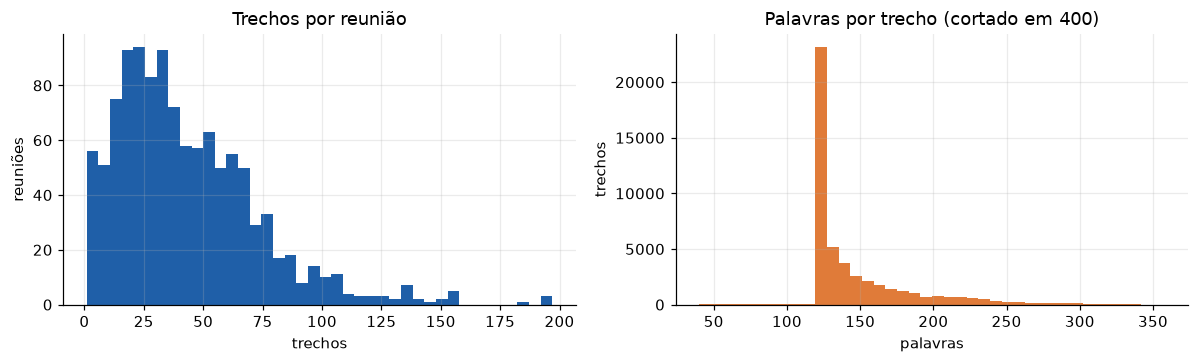

In [4]:
segments_cache = ARTIFACTS / "segments.pkl"
if segments_cache.exists():
    segments = pd.read_pickle(segments_cache)
else:
    segments = build_segments(meetings)
    ARTIFACTS.mkdir(exist_ok=True)
    segments.to_pickle(segments_cache)
per_meeting = segments.groupby("meeting_id").size()
print(f"Trechos: {len(segments):,} | por reunião: mediana {per_meeting.median():.0f}, "
      f"máx {per_meeting.max()} | palavras por trecho: mediana {segments['words'].median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(per_meeting, bins=40, color=PALETTE["primary"])
axes[0].set(title="Trechos por reunião", xlabel="trechos", ylabel="reuniões")
axes[1].hist(segments["words"].clip(upper=400), bins=40, color=PALETTE["secondary"])
axes[1].set(title="Palavras por trecho (cortado em 400)", xlabel="palavras", ylabel="trechos")
fig.tight_layout()
fig.savefig(FIGURES / "01_segmentacao.png", bbox_inches="tight")

### 1.3 Produtos e concorrentes (dicionário de entidades)

Produto mencionado é um problema de **reconhecimento de entidade** com vocabulário fechado, não de
classificação: um dicionário com as variantes que o reconhecimento de voz produz (*Protheus* aparece
como "proteus" em 99% dos casos) é exato e auditável. O mesmo vale para concorrentes.

In [5]:
prod_counts, comp_counts, meetings_with = {}, {}, {}
for mid, grp in segments.groupby("meeting_id"):
    found = find_products(" ".join(grp["clean"]))
    for p, n in found.items():
        prod_counts[p] = prod_counts.get(p, 0) + n
        meetings_with[p] = meetings_with.get(p, 0) + 1
    for c, n in find_competitors(" ".join(grp["clean"])).items():
        comp_counts[c] = comp_counts.get(c, 0) + n
products_table = (pd.DataFrame({"mencoes": prod_counts, "reunioes": meetings_with})
                  .sort_values("reunioes", ascending=False))
products_table["% reunioes"] = 100 * products_table["reunioes"] / len(meetings)
print("Concorrentes/tecnologias citados:", comp_counts)
products_table

Concorrentes/tecnologias citados: {'Oracle': 254, 'Salesforce': 7, 'Omie': 12}


,mencoes,reunioes,% reunioes
Protheus,3888,479,42.540
RM,1712,297,26.377
Fluig,1251,169,15.009
RD Station,65,47,4.174
TOTVS Cloud,135,27,2.398
Datasul,25,20,1.776
TOTVS Techfin,9,8,0.710
Logix,4,4,0.355


## 2. Modelo final selecionado e justificativa (15 pts) — parte 1: preparação da variável-alvo e análise das classes

A base **não tem rótulo por trecho**. Os alvos foram construídos por **supervisão fraca**
(*weak supervision*): funções de rotulagem escritas à mão — padrões de expressão regular sobre o
texto normalizado (`nora_insights/lexicons.py`) — que geram rótulos "prata":

| Tarefa | Classe positiva quando o trecho contém... | Exemplos de padrões |
|---|---|---|
| **Risco de churn** (risco / neutro) | linguagem de cancelamento, insatisfação, falha ou troca de fornecedor | "cancelamento", "insatisf…", "não funciona", "lentidão", "chamado aberto", "trocar de sistema" |
| **Oportunidade comercial** (sim / não) | linguagem de compra, proposta, expansão ou próximo passo | "proposta comercial", "enviar proposta", "licenças", "investimento", "expandir", "próximos passos", "prova de conceito" |
| **Sentimento** (positivo / neutro / negativo) | saldo de termos positivos e negativos, tratando negação ("sem problema" não é queixa) | "ótimo", "excelente", "resolveu" × "problema", "erro", "demora" |

**Uma armadilha específica da TOTVS.** Na primeira versão do léxico, "cotação", "comprar",
"pedido" e "contratação" marcavam oportunidade — e um treinamento do módulo de Compras virava
"oportunidade quente". Em reuniões de ERP essas palavras descrevem o processo **do cliente** que
está sendo demonstrado (a cotação com fornecedores dele; no RM, a contratação de funcionários), não
uma compra da TOTVS. Agora elas só contam quando o objeto é a solução ("contratar o módulo",
"adquirir a licença"), e "proposta" só conta como "proposta comercial", "enviar a proposta" etc.
Com isso a classe positiva caiu de 23% para cerca de 10% dos trechos, e ficou mais limpa.

O mesmo vale para "licença": em reuniões do RM, "licença-maternidade" e "licença médica" são o
assunto da demonstração, não licenças de software — e na primeira execução "maternidade" e
"proventos" apareceram entre os termos mais associados a oportunidade. O padrão agora exclui as
licenças de RH.

**O cuidado central — mascaramento.** Se o modelo fosse treinado com o texto original, ele apenas
reaprenderia a regex que gerou o rótulo, e as métricas seriam altíssimas e inúteis (a seção 3.2 mostra
a linha "sem máscara" como referência). Por isso
**as expressões de rotulagem são removidas do texto de entrada** antes do treino: o modelo precisa
aprender o **contexto** em que risco e oportunidade aparecem (o vocabulário ao redor), que é
justamente o que permite pontuar um trecho que não usa nenhuma das palavras da lista. A seção 3
mostra o tamanho da diferença.

30 padrões de risco, 26 padrões de oportunidade

              Risco de churn  Oportunidade  Sentimento
negativo                 0.0           0.0        17.4
neutro                  97.0           0.0        73.5
não oport.               0.0          90.4         0.0
oportunidade             0.0           9.6         0.0
positivo                 0.0           0.0         9.1
risco                    3.0           0.0         0.0


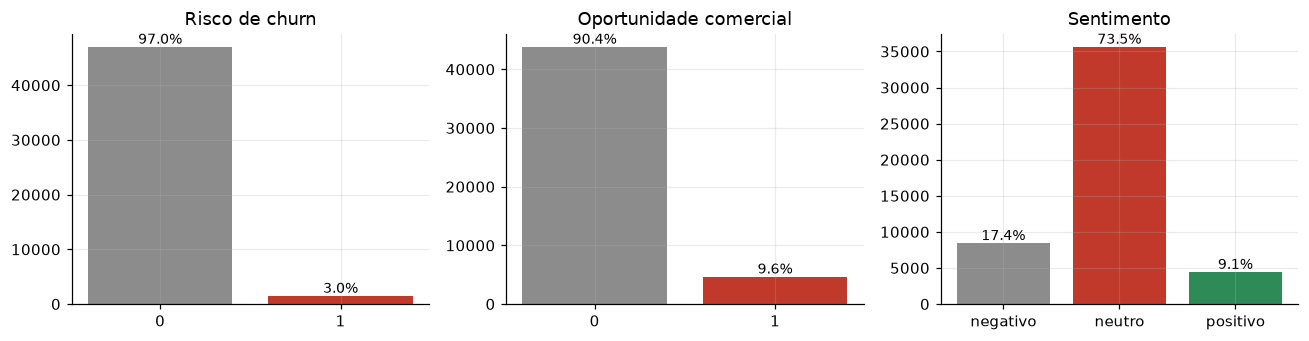

In [6]:
print(f"{len(RISK_PATTERNS)} padrões de risco, {len(OPPORTUNITY_PATTERNS)} padrões de oportunidade\n")
dist = pd.DataFrame({
    "Risco de churn": segments["risk"].map({1: "risco", 0: "neutro"}).value_counts(normalize=True),
    "Oportunidade": segments["opportunity"].map({1: "oportunidade", 0: "não oport."}).value_counts(normalize=True),
    "Sentimento": segments["sentiment"].value_counts(normalize=True),
}).fillna(0)
print((100 * dist).round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (title, col, order) in zip(axes, [
        ("Risco de churn", "risk", [0, 1]), ("Oportunidade comercial", "opportunity", [0, 1]),
        ("Sentimento", "sentiment", ["negativo", "neutro", "positivo"])]):
    vc = segments[col].value_counts().reindex(order)
    ax.bar([str(i) for i in vc.index], vc.values,
           color=[PALETTE["neutral"], PALETTE["bad"], PALETTE["ok"]][:len(vc)])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{100 * v / len(segments):.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
fig.tight_layout()
fig.savefig(FIGURES / "02_classes.png", bbox_inches="tight")

**Desbalanceamento.** Risco de churn é a classe rara (≈3% dos trechos) — o que é esperado numa base
dominada por reuniões de pré-venda e implantação. Em vez de reamostrar (o que duplicaria trechos
quase idênticos da mesma reunião e vazaria informação entre treino e teste), o balanceamento é feito
**por peso de classe** (`class_weight="balanced"` na Regressão Logística e
`"balanced_subsample"` na Random Forest; o Naive Bayes usado é o *Complement NB*, a variante
indicada para classes desbalanceadas) e **pela escolha do limiar de decisão** (seção 3.2).
Accuracy, nessa situação, é enganosa: um modelo que diz "neutro" sempre acerta 97%.

## 3. Modelo final selecionado e justificativa (15 pts) — parte 2: construção, avaliação e escolha dos modelos

**Protocolo.** Toda divisão é **agrupada por reunião**: nenhum trecho de uma reunião de teste é
visto no treino. Assim, as métricas descrevem o comportamento em uma **transcrição nova**, que é o
uso real.

* 80% das reuniões para treino e 20% (≈225 reuniões) para teste final, nunca usadas na seleção;
* nas reuniões de treino, **validação cruzada agrupada em 3 dobras** compara três algoritmos com o
  mesmo vetorizador TF-IDF (unigramas + bigramas, *sublinear tf*):
  **Naive Bayes (Complement)**, **Regressão Logística** e **Random Forest** (sobre os 5.000 termos
  de maior χ²);
* critério de seleção: **PR-AUC** nas tarefas binárias (independe de limiar e é a métrica adequada
  quando a classe positiva é rara) e **F1-macro** no sentimento.

In [7]:
train_idx, test_idx = group_split(segments)
print(f"Treino: {segments.iloc[train_idx]['meeting_id'].nunique()} reuniões / {len(train_idx):,} trechos")
print(f"Teste : {segments.iloc[test_idx]['meeting_id'].nunique()} reuniões / {len(test_idx):,} trechos")

results = {}
for task in TASKS:
    t = time.time()
    results[task] = compare_models(segments, task, train_idx, test_idx)
    print(f"{TASKS[task]['name']}: {time.time() - t:.0f}s — selecionado: {results[task]['selected']}")

Treino: 900 reuniões / 38,822 trechos
Teste : 226 reuniões / 9,615 trechos


Risco de churn: 123s — selecionado: Random Forest


Oportunidade comercial: 131s — selecionado: Random Forest


Sentimento: 183s — selecionado: Random Forest


### 3.1 Comparação na validação cruzada (reuniões de treino)

In [8]:
def cv_table(task: str) -> pd.DataFrame:
    cv = results[task]["cv"]
    out = pd.DataFrame(index=cv.index)
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
        out[m] = cv[f"{m}_media"].map("{:.3f}".format) + " ± " + cv[f"{m}_dp"].map("{:.3f}".format)
    return out


for task in TASKS:
    print(f"\n=== {TASKS[task]['name']} (média ± desvio nas 3 dobras; "
          f"{'binário: métricas da classe positiva' if task != 'sentiment' else 'macro-média'}) ===")
    print(cv_table(task).to_string())


=== Risco de churn (média ± desvio nas 3 dobras; binário: métricas da classe positiva) ===
                          accuracy      precision         recall             f1        roc_auc         pr_auc
modelo                                                                                                       
Naive Bayes          0.478 ± 0.003  0.038 ± 0.004  0.699 ± 0.040  0.072 ± 0.008  0.643 ± 0.025  0.124 ± 0.021
Regressao Logistica  0.665 ± 0.011  0.058 ± 0.004  0.699 ± 0.033  0.107 ± 0.007  0.759 ± 0.015  0.256 ± 0.041
Random Forest        0.656 ± 0.018  0.057 ± 0.005  0.698 ± 0.066  0.105 ± 0.010  0.755 ± 0.032  0.275 ± 0.053

=== Oportunidade comercial (média ± desvio nas 3 dobras; binário: métricas da classe positiva) ===
                          accuracy      precision         recall             f1        roc_auc         pr_auc
modelo                                                                                                       
Naive Bayes          0.860 ± 0.003  0.

### 3.2 Avaliação no conjunto de teste (reuniões nunca vistas)

**Limiar de decisão.** Os modelos devolvem probabilidade; o limiar é escolhido nas previsões
*out-of-fold* do treino, nunca no teste:

* **Risco de churn → prioriza Recall.** O maior limiar que ainda recupera **≥ 70%** dos trechos de
  risco. Um alerta falso custa uma ligação do Customer Success; um churn não percebido custa o
  contrato. Nessa assimetria, deixar passar é pior que alarmar à toa.
* **Oportunidade → maximiza F1.** Aqui os dois erros têm custo parecido: o vendedor perde tempo com
  falsa oportunidade, ou deixa uma real esfriar.

In [9]:
test_rows = []
for task in TASKS:
    for name, ev in results[task]["test"].items():
        row = ev.row()
        row["tarefa"] = TASKS[task]["name"]
        row["selecionado"] = "✔" if name == results[task]["selected"] else ""
        test_rows.append(row)
    ceiling = unmasked_ceiling(segments, task, train_idx, test_idx)
    row = ceiling.row()
    row["tarefa"] = TASKS[task]["name"]
    row["selecionado"] = "(referência)"
    test_rows.append(row)
test_table = pd.DataFrame(test_rows).set_index(["tarefa", "modelo"])
test_table[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "threshold", "selecionado"]]

accuracy  precision  \
tarefa                 modelo                                                   
Risco de churn         Naive Bayes                           0.242      0.039   
                       Regressao Logistica                   0.666      0.071   
                       Random Forest                         0.676      0.071   
                       Regressao Logistica (sem mascara)     0.987      0.866   
Oportunidade comercial Naive Bayes                           0.796      0.250   
                       Regressao Logistica                   0.884      0.411   
                       Random Forest                         0.917      0.598   
                       Regressao Logistica (sem mascara)     0.982      0.906   
Sentimento             Naive Bayes                           0.640      0.481   
                       Regressao Logistica                   0.649      0.502   
                       Random Forest                         0.781      0.680   
                       Regressao Logistica (sem mascara)     0.926      0.888   

                                                          recall     f1  \
tarefa                 modelo                                             
Risco de churn         Naive Bayes                         0.900  0.075   
                       Regressao Logistica                 0.720  0.129   
                       Random Forest                       0.705  0.130   
                       Regressao Logistica (sem mascara)   0.745  0.801   
Oportunidade comercial Naive Bayes                         0.567  0.347   
                       Regressao Logistica                 0.497  0.450   
                       Random Forest                       0.411  0.487   
                       Regressao Logistica (sem mascara)   0.911  0.908   
Sentimento             Naive Bayes                         0.519  0.490   
                       Regressao Logistica                 0.566  0.520   
                       Random Forest                       0.536  0.579   
                       Regressao Logistica (sem mascara)   0.890  0.889   

                                                          roc_auc  pr_auc  \
tarefa                 modelo                                               
Risco de churn         Naive Bayes                          0.684   0.105   
                       Regressao Logistica                  0.773   0.274   
                       Random Forest                        0.777   0.363   
                       Regressao Logistica (sem mascara)    0.956   0.841   
Oportunidade comercial Naive Bayes                          0.773   0.358   
                       Regressao Logistica                  0.810   0.409   
                       Random Forest                        0.821   0.543   
                       Regressao Logistica (sem mascara)    0.992   0.961   
Sentimento             Naive Bayes                          0.707   0.505   
                       Regressao Logistica                  0.735   0.533   
                       Random Forest                        0.766   0.618   
                       Regressao Logistica (sem mascara)    0.967   0.933   

                                                          threshold  \
tarefa                 modelo                                         
Risco de churn         Naive Bayes                            0.045   
                       Regressao Logistica                    0.139   
                       Random Forest                          0.138   
                       Regressao Logistica (sem mascara)      0.500   
Oportunidade comercial Naive Bayes                            0.397   
                       Regressao Logistica                    0.592   
                       Random Forest                          0.447   
                       Regressao Logistica (sem mascara)      0.500   
Sentimento             Naive Bayes                              NaN   
            

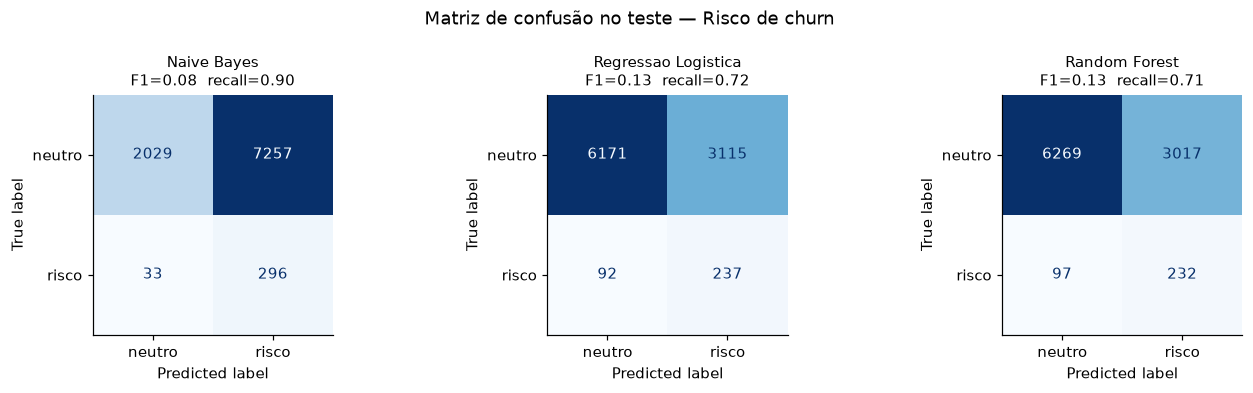

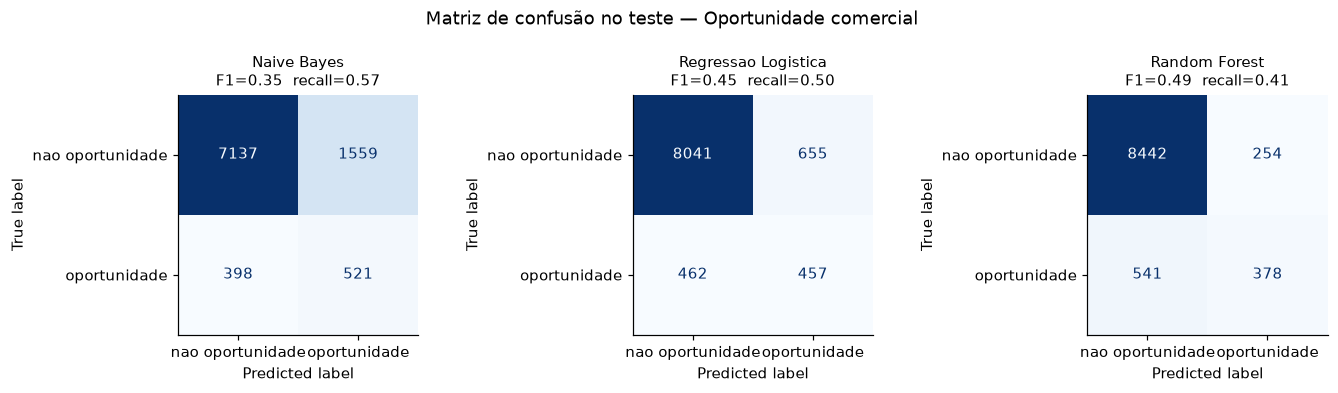

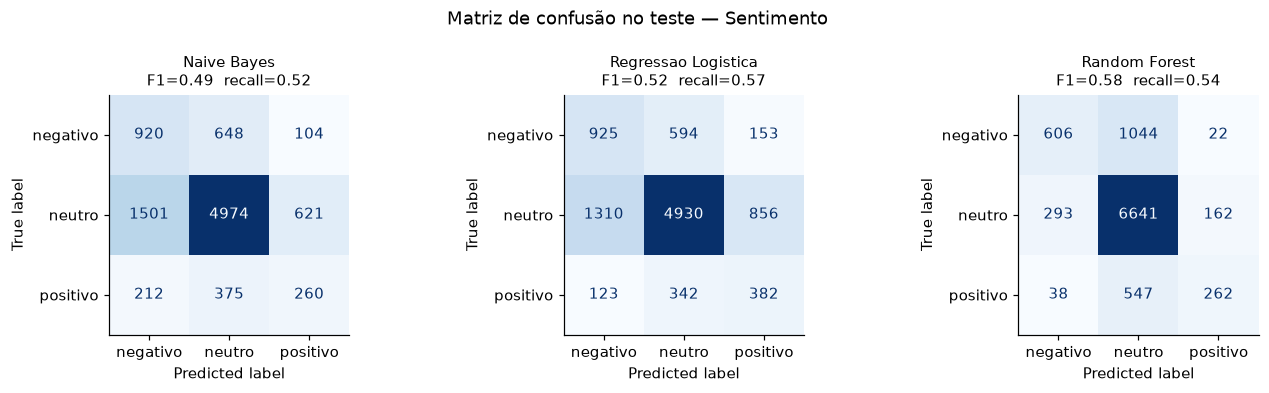

In [10]:
for task in TASKS:
    fig = confusion_grid(results[task]["test"], TASKS[task]["label_names"],
                         f"Matriz de confusão no teste — {TASKS[task]['name']}")
    fig.savefig(FIGURES / f"03_confusao_{task}.png", bbox_inches="tight")

### 3.3 Interpretabilidade do modelo final

Termos de maior peso na Regressão Logística — lembrando que **as palavras da regra foram
mascaradas**, então o que aparece aqui é o contexto que o modelo aprendeu sozinho. Palavras escritas
com inicial maiúscula no meio da frase (nomes próprios que a anonimização deixou passar) são
omitidas da exibição.

In [11]:
proper_nouns: set[str] = set()
for raw_text in segments["text"]:
    proper_nouns |= _proper_nouns(raw_text)


# Residual names that reach the transcript already lower-cased, so the capitalization test misses them.
RESIDUAL_NAMES = {"montanini", "raulino"}


def shown(terms: list[tuple[str, float]], n: int) -> str:
    kept = [t for t, _ in terms if not set(t.split()) & proper_nouns][:n]
    return ", ".join("[nome]" if t in RESIDUAL_NAMES else t for t in kept)


for task in ("risk", "opportunity"):
    lr = results[task]["fitted"]["Regressao Logistica"]
    feats = top_features(lr, task, n=40)
    print(f"\n{TASKS[task]['name']} — termos que mais empurram para a classe positiva:")
    print(shown(feats["positiva"], 15))
lr = results["sentiment"]["fitted"]["Regressao Logistica"]
for cls, terms in top_features(lr, "sentiment", n=40).items():
    print(f"\nSentimento {cls}: " + shown(terms, 12))


Risco de churn — termos que mais empurram para a classe positiva:
cancelar, funcionar, problema, [nome], cancelamentos, cancelado, travou, adianto, chamado, situacao, funcionando, exclusao, funcionava, ganhando, carencia

Oportunidade comercial — termos que mais empurram para a classe positiva:
licenciamento, proposta, preco, proventos, visao, dar, capex, quantidade, licenciado, bonificacao, margem, cobra, valorizar, retorno, investir

Sentimento negativo: correr, reprocessar, trava, vezes, memoria, regularizar, impactar, anos, correndo, errado, qualidade, semanas

Sentimento neutro: estrategia, conseguir dar, interessa, procurando, aprovado, bases, porcentagem, definicoes, chegar momento, monitoramento, simulacao, cadastros

Sentimento positivo: pareca, conseguisse, queira, modular, traga, encaminhado, [nome], procuro, agradeco, obrigatoriamente, americano, modulos


O vocabulário de **risco** é o esperado — falhas, chamados, ouvidoria, cobrança, "nunca", "travou" —
e confirma que o modelo aprendeu o entorno da insatisfação sem ver as palavras da regra. O de
**sentimento positivo** é o mais fraco dos três: o léxico positivo é pequeno e a cortesia foi
deliberadamente excluída, então o modelo tem pouco sinal para aprender — coerente com o F1 mais baixo
da classe positiva na matriz de confusão.

### 3.4 Análise dos erros

Falsos positivos e falsos negativos do modelo selecionado de **risco de churn**, no teste.

In [12]:
task = "risk"
sel = results[task]["selected"]
thr = results[task]["thresholds"][sel]
test = segments.iloc[test_idx].copy()
x_test = test["clean"].map(lambda c: mask(c, ("risk",)))
test["p"] = scores(results[task]["fitted"][sel], x_test, task)
fp = test[(test["p"] >= thr) & (test["risk"] == 0)].sort_values("p", ascending=False)
fn = test[(test["p"] < thr) & (test["risk"] == 1)].sort_values("p")
print(f"Limiar {thr:.3f} | falsos positivos: {len(fp)} | falsos negativos: {len(fn)}\n")
print("FALSOS POSITIVOS (modelo viu risco, regra não):")
for _, r in fp.head(5).iterrows():
    print(f"  p={r['p']:.2f}  {scrub(r['text'])}")
print("\nFALSOS NEGATIVOS (regra marcou risco, modelo não):")
for _, r in fn.head(5).iterrows():
    print(f"  p={r['p']:.2f}  {scrub(r['text'])}")

Limiar 0.138 | falsos positivos: 3017 | falsos negativos: 97

FALSOS POSITIVOS (modelo viu risco, regra não):
  p=0.49  Tá, então vamos lá. Se o RH vê que... [LOCAL] que tem necessidade dela por mais três meses. Então eu já peço esse encerramento e vocês vão fazer um novo contrato por três meses para 2016. Não, é o mesmo. É que nesse contrato consta aviso prévio. Nós vamos faze ...
  p=0.48  A gente consegue tratar duas áreas ao mesmo tempo, com uma precificação só. Então, de repente, eu queria ver se você tem, além do RH, alguma demanda fiscal, contábil, financeira, de repente? A gente não tem hoje, [PESSOA]. As outras áreas a gente tá conseguind ...
  p=0.45  Já pula pra 21, depois volta pra 20, se tiver alguma dúvida. Mas sempre dá uma sequência e volta, uma sequência e volta. Se precisar, né? Que às vezes a próxima pode ajudar a pronunciar a anterior. Tá, entendi. Vamos falar sobre o burdich. Eu não gostaria de c ...
  p=0.45  para a gente pede para a [LOCAL] pelo menos estão no ja

In [13]:
def pattern_counts(frame: pd.DataFrame) -> pd.Series:
    counts: dict[str, int] = {}
    for c in frame["clean"]:
        for p in RISK_PATTERNS:
            if re.search(p, c):
                counts[p[:40]] = counts.get(p[:40], 0) + 1
    return pd.Series(counts, dtype=int)


tp = test[(test["p"] >= thr) & (test["risk"] == 1)]
print("Padrões da regra presentes nos falsos negativos × verdadeiros positivos:")
pd.DataFrame({"falsos negativos": pattern_counts(fn), "verdadeiros positivos": pattern_counts(tp)}) \
    .fillna(0).astype(int).sort_values("falsos negativos", ascending=False).head(10)

Padrões da regra presentes nos falsos negativos × verdadeiros positivos:


,falsos negativos,verdadeiros positivos
\bnao\s+(esta\s+|ta\s+)?funciona\w*,23,37
\breclama\w*,12,27
\btravand\w*,11,12
\babsurd[oa]\b,8,28
\blentid\w*,8,12
\bcancelamento\b,7,32
\bprejuizo\w*,7,11
\bfrustra\w*,5,10
\brescis\w*,5,13
\btrocar\s+de\s+(sistema|fornecedor|erp|,2,9


**O que os erros mostram.**

* **Falsos negativos (a regra viu risco, o modelo não) são, na maioria, erros da regra.** Lidos um a
  um, são trechos de **demonstração de produto** em que a palavra da lista aparece com outro
  sentido: "probabilidade de **rescisão**" é uma funcionalidade do RH que prevê pedido de demissão;
  "maior **prejuízo**" é um relatório de rentabilidade; "o sistema **não funciona** só dentro da
  integração" é uma frase positiva. O modelo dá probabilidade baixa a esses trechos porque o contexto
  é de apresentação de tela, e está certo. É o mesmo fenômeno encontrado no léxico de oportunidade
  (seção 2): o vocabulário do ERP colide com o vocabulário de risco e de venda.
* **Falsos positivos (o modelo viu risco, a regra não) são mistos.** Parte é **atrito real que a lista
  não cobre** — "cobrança indevida", "deu problema depois da atualização", "não gostei da agenda" —,
  ou seja, o modelo generalizou para além da regra, que é o objetivo do mascaramento. Outra parte é
  **erro genuíno**: conversas operacionais sobre "cancelar a nota fiscal", em que o modelo associa
  "cancelar" a risco porque, no rótulo, "cancelamento" quase sempre é de contrato.
* **O preço do limiar.** Com recall ≥ 70%, a precisão por trecho fica baixa (cerca de 7%, contra uma
  taxa-base de ≈3%: o modelo concentra o risco ~2 vezes acima do acaso nessa faixa, e a PR-AUC é
  ~10 vezes a taxa-base). Isso é aceitável **porque a decisão não é tomada por trecho**: a seção 4
  agrega dezenas de trechos por reunião e combina o modelo com a regra, e um trecho falso isolado
  pesa pouco no score da reunião.

É por isso que a pontuação final **combina as duas fontes** (seção 4) em vez de escolher uma: a regra
é precisa onde é inequívoca ("cancelar o contrato", "sair da TOTVS"), e o modelo cobre o que a lista
não previu.

### 3.5 Modelo final e justificativa

**Random Forest foi selecionada nas três tarefas.** Ela tem a maior PR-AUC (binárias) e o maior
F1-macro (sentimento) na validação cruzada, e a vantagem se mantém — ou aumenta — no teste com
reuniões nunca vistas. No risco de churn a diferença para a Regressão Logística na validação cruzada é
pequena (praticamente empate dentro do desvio entre dobras), mas no teste a Random Forest separa
melhor os trechos mais arriscados (PR-AUC maior), que são justamente os que viram evidência na tela.
O Naive Bayes fica atrás em todas: com classes raras, ele só atinge o recall exigido com um limiar
tão baixo que marca quase tudo como risco.

**Qual métrica importa em cada problema:**

| Tarefa | Métrica decisiva | Por quê |
|---|---|---|
| Risco de churn | **Recall** (com PR-AUC para comparar modelos) | O custo é assimétrico: perder um cliente que deu sinais custa o contrato; um alerta falso custa uma ligação. Accuracy é inútil com 3% de positivos. |
| Oportunidade | **F1** (equilíbrio precisão × recall) | Os dois erros custam tempo do vendedor: correr atrás de falsa oportunidade, ou deixar uma real esfriar. |
| Sentimento | **F1-macro** | "Neutro" domina; a macro-média obriga o modelo a acertar também positivo e negativo, que são os que informam. |

**O que se perde ao escolher a Random Forest:** interpretabilidade direta (por isso a seção 3.3 usa
os pesos da Regressão Logística para explicar o vocabulário) e custo de treino maior. O custo de
inferência é irrelevante — uma reunião inteira é analisada em ~0,2 s.

In [14]:
summary = []
for task in TASKS:
    sel = results[task]["selected"]
    ev = results[task]["test"][sel]
    cv = results[task]["cv"].loc[sel]
    summary.append({"tarefa": TASKS[task]["name"], "modelo final": sel,
                    "critério (CV)": f"{results[task]['selection_metric'].replace('_media', '')} = "
                                     f"{cv[results[task]['selection_metric']]:.3f}",
                    "precision (teste)": ev.precision, "recall (teste)": ev.recall,
                    "f1 (teste)": ev.f1, "accuracy (teste)": ev.accuracy})
selected = {task: results[task]["selected"] for task in TASKS}
thresholds = {task: results[task]["thresholds"][selected[task]] for task in TASKS}
pd.DataFrame(summary).set_index("tarefa")

,modelo final,critério (CV),precision (teste),recall (teste),f1 (teste),accuracy (teste)
tarefa,,,,,,
Risco de churn,Random Forest,pr_auc = 0.275,0.071,0.705,0.130,0.676
Oportunidade comercial,Random Forest,pr_auc = 0.482,0.598,0.411,0.487,0.917
Sentimento,Random Forest,f1 = 0.546,0.680,0.536,0.579,0.781


## 4. Sistema de scoring/indicadores (20 pts)

**Do trecho à reunião.** Para cada trecho de uma nova transcrição:

* **Score do trecho** = combinação *noisy-OR* do modelo com a regra:
  `s = 1 − (1 − p_modelo) · (1 − 0,6 · regra)`. A regra é precisa mas estreita; o modelo generaliza
  mas é ruidoso. O *noisy-OR* trata as duas como evidências independentes: qualquer uma eleva o
  score, e as duas juntas elevam mais.
* **Polaridade do trecho** = `0,7 · (P(positivo) − P(negativo)) + 0,3 · sinal(léxico)`, em [−1, 1].

**Na reunião:**

| Indicador | Cálculo | Escala |
|---|---|---|
| **Risco de churn** | `0,5 · média dos 10% trechos mais arriscados + 0,5 · média geral` → **percentil** na base TOTVS | 0–100 |
| **Oportunidade comercial** | idem, sobre os scores de oportunidade | 0–100 |
| **Índice de sentimento** | `100 · média da polaridade`, mais **tendência** (último terço − primeiro terço) | −100 a +100 |
| **Prioridade** | `max(risco, oportunidade)` — ordena a fila do time comercial | 0–100 |
| **Classificação da conta** | regra sobre os níveis: Alto ≥ 80, Médio ≥ 50 | 5 classes |

Misturar pico e média evita dois erros: uma reunião longa e saudável com um único momento ruim não
vira "risco alto", e uma reunião inteira morna não passa despercebida.

**Por que percentil.** O modelo foi treinado com rótulos fracos, então a probabilidade dele não é
calibrada como "chance de cancelar". O percentil diz algo honesto e útil: *"esta reunião tem mais
sinal de risco do que 85% das 1.126 reuniões da base"* — e é exatamente isso que um time precisa
para priorizar uma fila. A distribuição de referência é calculada **out-of-fold** (cada reunião
pontuada por um modelo que não a viu), para não ficar otimista.

In [15]:
t = time.time()
oof = out_of_fold_meetings(segments, meetings, selected)
ref_risk = np.sort(oof["risk_raw"].to_numpy())
ref_opp = np.sort(oof["opportunity_raw"].to_numpy())
oof["risco"] = 100 * oof["risk_raw"].rank(pct=True)
oof["oportunidade"] = 100 * oof["opportunity_raw"].rank(pct=True)
print(f"Scores out-of-fold de {len(oof)} reuniões em {time.time() - t:.0f}s")


def account_status(r):
    risk, opp = level(r["risco"]), level(r["oportunidade"])
    if risk == "Alto" and opp == "Alto":
        return "Negociação sensível"
    if risk == "Alto":
        return "Conta em risco"
    if opp == "Alto":
        return "Oportunidade quente"
    if risk == "Medio" or r["sentiment_index"] <= -10:
        return "Atenção"
    return "Saudável / acompanhamento"


oof["classificacao"] = oof.apply(account_status, axis=1)
print(oof["classificacao"].value_counts().to_string())
print(f"\nCorrelação de Spearman risco × oportunidade: "
      f"{spearmanr(oof['risk_raw'], oof['opportunity_raw']).statistic:.2f}")
print(f"Correlação de Spearman risco × sentimento:    "
      f"{spearmanr(oof['risk_raw'], oof['sentiment_index']).statistic:.2f}")

Scores out-of-fold de 1126 reuniões em 407s
classificacao
Saudável / acompanhamento    373
Atenção                      355
Oportunidade quente          172
Conta em risco               172
Negociação sensível           54

Correlação de Spearman risco × oportunidade: 0.09
Correlação de Spearman risco × sentimento:    -0.57


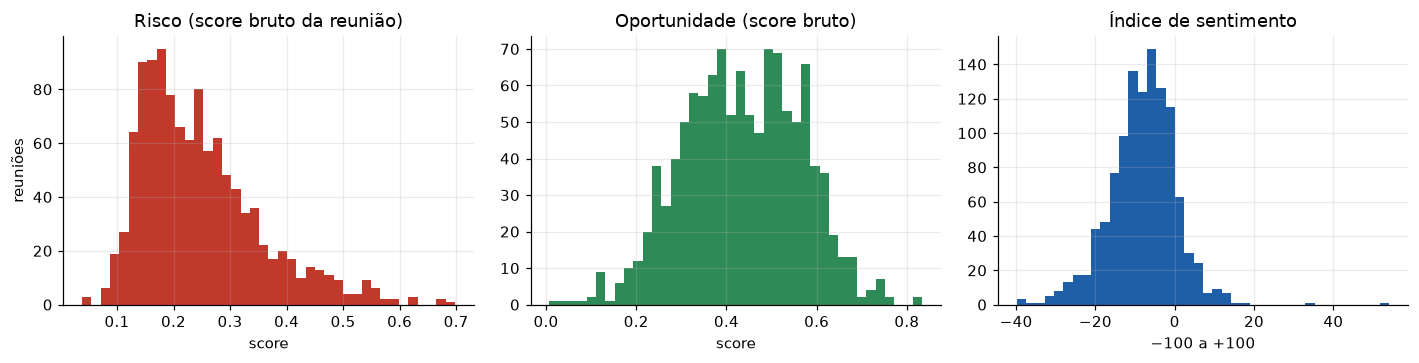

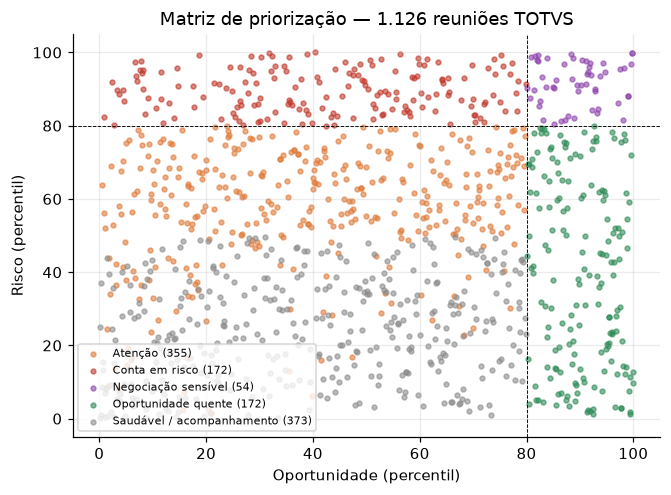

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(oof["risk_raw"], bins=40, color=PALETTE["bad"])
axes[0].set(title="Risco (score bruto da reunião)", xlabel="score", ylabel="reuniões")
axes[1].hist(oof["opportunity_raw"], bins=40, color=PALETTE["ok"])
axes[1].set(title="Oportunidade (score bruto)", xlabel="score")
axes[2].hist(oof["sentiment_index"], bins=40, color=PALETTE["primary"])
axes[2].set(title="Índice de sentimento", xlabel="−100 a +100")
fig.tight_layout()
fig.savefig(FIGURES / "04_distribuicao_scores.png", bbox_inches="tight")

fig, ax = plt.subplots(figsize=(6.2, 4.6))
colors = {"Conta em risco": PALETTE["bad"], "Oportunidade quente": PALETTE["ok"],
          "Negociação sensível": "#8e44ad", "Atenção": PALETTE["secondary"],
          "Saudável / acompanhamento": PALETTE["neutral"]}
for cls, grp in oof.groupby("classificacao"):
    ax.scatter(grp["oportunidade"], grp["risco"], s=10, alpha=0.6, label=f"{cls} ({len(grp)})",
               color=colors[cls])
ax.axhline(80, color="k", lw=0.6, ls="--")
ax.axvline(80, color="k", lw=0.6, ls="--")
ax.set(xlabel="Oportunidade (percentil)", ylabel="Risco (percentil)",
       title="Matriz de priorização — 1.126 reuniões TOTVS")
ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES / "05_matriz_priorizacao.png", bbox_inches="tight")

## 5. Protótipo funcional (20 pts)

O pipeline inteiro está empacotado em `nora_insights/pipeline.py` (`NoraInsights.analyze`) e
exposto de duas formas:

* **CLI** — `python analyze.py reuniao.txt` (ou `--json` para a saída completa);
* **Aplicação web** — `streamlit run app.py`: colar texto, enviar `.txt/.vtt/.srt` ou escolher um
  exemplo; mostra indicadores, recomendações, produtos, termos, a curva de sentimento ao longo da
  reunião e os trechos que justificam cada score.

Primeiro treinamos os modelos finais com **todas** as reuniões e salvamos o pacote que a CLI e o app
carregam:

In [17]:
metrics = {task: {"selected": selected[task], "threshold": thresholds[task],
                  "test": {k: v.row() for k, v in results[task]["test"].items()},
                  "cv": results[task]["cv"].reset_index().to_dict(orient="records")} for task in TASKS}
bundle = build_bundle(segments, meetings, selected, thresholds, oof, metrics)
joblib.dump(bundle, BUNDLE, compress=3)
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float), encoding="utf-8")
oof.to_csv(ARTIFACTS / "meetings_oof.csv")
nora = NoraInsights.load()
print(f"Pacote salvo em {BUNDLE.name} — modelos: {bundle['meta']['selected']}")

Pacote salvo em nora_insights.joblib — modelos: {'risk': 'Random Forest', 'opportunity': 'Random Forest', 'sentiment': 'Random Forest'}


Saída completa para uma reunião nova (sintética, nunca vista no treino). Os campos pedidos no enunciado estão nas chaves:

| Pedido no enunciado | Chave na saída |
|---|---|
| Produto identificado | `produtos_identificados` |
| Sentimento | `indicadores.sentimento` (índice, rótulo, tendência) |
| Risco de churn | `indicadores.risco_churn` (score 0–100, nível) |
| Oportunidade comercial | `indicadores.oportunidade_comercial` (score 0–100, nível) |
| Principais termos encontrados | `principais_termos` |
| Recomendação de ação | `recomendacoes` (ação, motivo, prioridade) + `evidencias` |

In [18]:
report = nora.analyze(synthetic["04-acme-churn-suporte-performance"])
print(json.dumps({k: v for k, v in report.items() if k not in ("trajetoria_sentimento", "evidencias")},
                 ensure_ascii=False, indent=2))
print("\nEvidência de risco mais forte:\n ", report["evidencias"]["risco"][0]["texto"])

{
  "resumo": {
    "turnos": 33,
    "locutores": 4,
    "segmentos": 6,
    "palavras": 856
  },
  "classificacao_conta": "Conta em risco",
  "indicadores": {
    "risco_churn": {
      "score": 99.7,
      "nivel": "Alto",
      "trechos_sinalizados": 5
    },
    "oportunidade_comercial": {
      "score": 4.5,
      "nivel": "Baixo",
      "trechos_sinalizados": 0
    },
    "sentimento": {
      "indice": -30.3,
      "rotulo": "negativo",
      "inicio": -37.4,
      "fim": -24.2,
      "tendencia": "estavel"
    },
    "prioridade": 99.7
  },
  "produtos_identificados": {},
  "concorrentes_citados": {},
  "principais_termos": [
    {
      "termo": "patch",
      "peso": 0.173
    },
    {
      "termo": "sla",
      "peso": 0.162
    },
    {
      "termo": "posso garantir",
      "peso": 0.136
    },
    {
      "termo": "assistido",
      "peso": 0.136
    },
    {
      "termo": "modulo fiscal",
      "peso": 0.135
    },
    {
      "termo": "multa",
      "peso": 0.128
   

## 6. Validação com novas transcrições (15 pts)

Quatro validações, todas com transcrições que os modelos não viram no treino:

1. **Reuniões TOTVS de teste** — as ≈225 reuniões nunca vistas da seção 3 (métricas por trecho).
2. **17 transcrições sintéticas do repositório** (6.1) — outro fornecedor (empresas fictícias), outro
   estilo de escrita, e cada uma com o **sinal esperado documentado** em `data/synthetic/README.md`
   antes deste trabalho existir. É um teste de generalização fora da distribuição.
3. **Três transcrições novas no formato TOTVS** (6.2) — demonstração ponta a ponta com produtos reais.
4. **NPS real** (6.3) — o único rótulo externo da base: o risco previsto é maior para detratores?

### 6.1 Transcrições sintéticas com sinal esperado

In [19]:
expected = {
    "01": "Oportunidade", "02": "Oportunidade", "03": "Oportunidade", "04": "Risco", "05": "Risco",
    "06": "Oportunidade", "07": "Oportunidade", "08": "Objeção", "09": "Oportunidade", "10": "Interna",
    "11": "Interna", "12": "Interna", "13": "Oportunidade", "14": "Objeção", "15": "Oportunidade",
    "16": "Oportunidade", "17": "Interna",
}
rows = []
for name, raw in synthetic.items():
    r = nora.analyze(raw)
    ind = r["indicadores"]
    rows.append({"reuniao": name[:38], "esperado": expected[name[:2]],
                 "risco": ind["risco_churn"]["score"], "oportunidade": ind["oportunidade_comercial"]["score"],
                 "sentimento": ind["sentimento"]["indice"], "classificacao": r["classificacao_conta"],
                 "produtos/concorrentes": ", ".join(list(r["produtos_identificados"]) +
                                                    list(r["concorrentes_citados"])) or "—",
                 "1a recomendacao": r["recomendacoes"][0]["acao"][:60]})
synth = pd.DataFrame(rows)
synth

,reuniao,esperado,risco,oportunidade,sentimento,classificacao,produtos/concorrentes,1a recomendacao
0,01-acme-discovery-lead-novo,Oportunidade,19.3,61.8,-6.0,Saudavel / acompanhamento,—,Registrar no CRM o produto de interesse
1,02-acme-followup-financeiro-pro,Oportunidade,7.5,77.9,-13.1,Atencao,—,Registrar no CRM o produto de interesse
2,03-acme-upsell-manufatura-concorrente,Oportunidade,90.1,75.0,-13.2,Conta em risco,—,Acionar Customer Success em ate 48h com um plano de acao par
3,04-acme-churn-suporte-performance,Risco,99.7,4.5,-30.3,Conta em risco,—,Acionar Customer Success em ate 48h com um plano de acao par
4,05-northwind-renewal-churn-risco,Risco,15.5,97.9,-12.1,Oportunidade quente,—,Enviar proposta comercial e agendar a proxima etapa em ate 5
5,06-northwind-prospect-poc,Oportunidade,1.0,95.9,8.3,Oportunidade quente,—,Enviar proposta comercial e agendar a proxima etapa em ate 5
6,07-northwind-qbr-cliente-saudavel,Oportunidade,24.3,97.5,3.0,Oportunidade quente,—,Enviar proposta comercial e agendar a proxima etapa em ate 5
7,08-northwind-objecao-integracao-tecnic,Objeção,6.7,87.0,-29.3,Oportunidade quente,—,Enviar proposta comercial e agendar a proxima etapa em ate 5
8,09-northwind-upsell-payments-risk,Oportunidade,12.5,97.7,-10.9,Oportunidade quente,—,Enviar proposta comercial e agendar a proxima etapa em ate 5
9,10-solo-standup-bug-agendamento,Interna,95.3,15.0,-22.4,Conta em risco,—,Acionar Customer Success em ate 48h com um plano de acao par


In [20]:
is_risk = (synth["esperado"] == "Risco").astype(int)
is_opp = (synth["esperado"] == "Oportunidade").astype(int)
commercial = synth["esperado"] != "Interna"
print(f"AUC risco  (Risco vs demais)              : {roc_auc_score(is_risk, synth['risco']):.2f}")
print(f"AUC oport. (Oportunidade vs Interna)      : "
      f"{roc_auc_score(is_opp[synth['esperado'].isin(['Oportunidade', 'Interna'])], synth.loc[synth['esperado'].isin(['Oportunidade', 'Interna']), 'oportunidade']):.2f}")
print(f"Sentimento médio — Risco: {synth.loc[is_risk == 1, 'sentimento'].mean():+.1f} | "
      f"Oportunidade: {synth.loc[is_opp == 1, 'sentimento'].mean():+.1f}")
print(synth.groupby("esperado")[["risco", "oportunidade", "sentimento"]].mean().round(1).to_string())

AUC risco  (Risco vs demais)              : 0.70
AUC oport. (Oportunidade vs Interna)      : 0.97
Sentimento médio — Risco: -21.2 | Oportunidade: -5.6
              risco  oportunidade  sentimento
esperado                                     
Interna        40.9          24.7       -11.1
Objeção        12.0          58.1       -23.5
Oportunidade   36.8          75.9        -5.6
Risco          57.6          51.2       -21.2


**Leitura.** O indicador de **oportunidade generaliza bem** para um fornecedor e um estilo de escrita
que o modelo nunca viu: separa quase perfeitamente as reuniões comerciais das internas. O de
**risco acerta o caso mais claro** (a reunião de crise 04 fica no topo da base) e erra dois de
forma instrutiva:

* **05 (renovação com risco de churn) sai com risco baixo e oportunidade alta.** O risco ali está em
  **pressão de preço e ameaça de concorrente** ("‑20%", proposta do concorrente), sem nenhuma das
  palavras de insatisfação da lista — e a conversa é, na superfície, uma negociação de renovação.
  É o limite de um rótulo construído por léxico: ele não captura risco expresso como barganha.
* **10 (stand-up interno sobre um bug) sai como "conta em risco".** O texto fala de falha, erro e
  hotfix — linguagem de problema — mas não há cliente na reunião. O pipeline não distingue reunião
  interna de reunião com cliente (ver Limitações).

Nenhum dos dois foi "corrigido" ajustando regras depois de visto: isso seria calibrar no próprio
conjunto de validação.

### 6.2 Três transcrições novas no formato TOTVS

Escritas para este entregável em `examples/`, no formato `[LOCUTOR N]` da base e citando produtos
reais (Protheus, RM, Fluig, Datasul) e um concorrente (SAP) — o que as sintéticas, de fornecedores
fictícios, não exercitam. São **casos de demonstração**, não uma amostra estatística: foram escritas
por quem conhece as regras, então medem se o pipeline encadeia as etapas corretamente, não quanto
ele generaliza (isso é a 6.1 e a 6.3).

In [21]:
for path in sorted(Path("examples").glob("*.txt")):
    r = nora.analyze(path.read_text(encoding="utf-8"))
    ind = r["indicadores"]
    print(f"\n### {path.stem} → {r['classificacao_conta']}")
    print(f"  risco {ind['risco_churn']['score']:.0f} ({ind['risco_churn']['nivel']}) | "
          f"oportunidade {ind['oportunidade_comercial']['score']:.0f} ({ind['oportunidade_comercial']['nivel']}) | "
          f"sentimento {ind['sentimento']['indice']:+.0f} ({ind['sentimento']['rotulo']})")
    print(f"  produtos: {r['produtos_identificados']} | concorrentes: {r['concorrentes_citados']}")
    print(f"  termos: {', '.join(t['termo'] for t in r['principais_termos'][:8])}")
    for rec in r["recomendacoes"]:
        print(f"  [{rec['prioridade']}] {rec['acao']} — {rec['motivo']}")


### novo-01-protheus-insatisfacao → Conta em risco
  risco 100 (Alto) | oportunidade 9 (Baixo) | sentimento -49 (negativo)
  produtos: {'Protheus': 1} | concorrentes: {'SAP': 1, 'Oracle': 1}
  termos: chamados, escalar, time sustentacao, implantacao folha, trazer bem, servidor proprio, sem resposta, bem agressivo
  [alta] Acionar Customer Success em ate 48h com um plano de acao para as dores citadas — Risco de churn 100/100 — mais sinal de risco que 99% das reunioes da base TOTVS; 3 trecho(s) sinalizado(s)
  [alta] Preparar comparativo (battlecard) frente a SAP, Oracle — Concorrente citado em reuniao com sinal de risco



### novo-02-rm-expansao-fluig → Oportunidade quente
  risco 7 (Baixo) | oportunidade 100 (Alto) | sentimento +7 (neutro)
  produtos: {'RM': 4, 'Fluig': 2} | concorrentes: {}
  termos: novas unidades, admissao, fluxo admissao, integra nativamente, problema ponto, gostou bastante, funcionando muito, trezentos
  [alta] Enviar proposta comercial e agendar a proxima etapa em ate 5 dias uteis — Oportunidade 100/100 — mais sinal de compra que 99% das reunioes; 3 trecho(s) com sinal de compra



### novo-03-datasul-treinamento → Saudavel / acompanhamento
  risco 0 (Baixo) | oportunidade 4 (Baixo) | sentimento +13 (positivo)
  produtos: {'Datasul': 1} | concorrentes: {}
  termos: requisitante, almoxarifado, tres fornecedores, cotacao, sessao, fornecedor sistema, informam, material escritorio
  [media] Fazer follow-up de satisfacao em ate uma semana — O sentimento caiu ao longo da reuniao (+26 no inicio, -0 no fim)
  [baixa] Manter a cadencia de relacionamento e registrar o resumo no CRM — Nenhum indicador em nivel alto


### 6.3 NPS real × risco previsto

Para cada reunião com NPS, o risco foi calculado **out-of-fold** (por um modelo que não viu aquela
reunião). Se o indicador captura algo real, detratores (NPS 0–6) devem ter risco maior.

Reuniões com NPS: 310 (detratores: 49)
Risco médio — detratores 49.2 | demais 54.3
AUC (risco separa detratores): 0.45 | Mann-Whitney unilateral p = 0.861
Spearman risco × NPS: -0.02 (p = 0.675) | sentimento × NPS: +0.07 (p = 0.226)


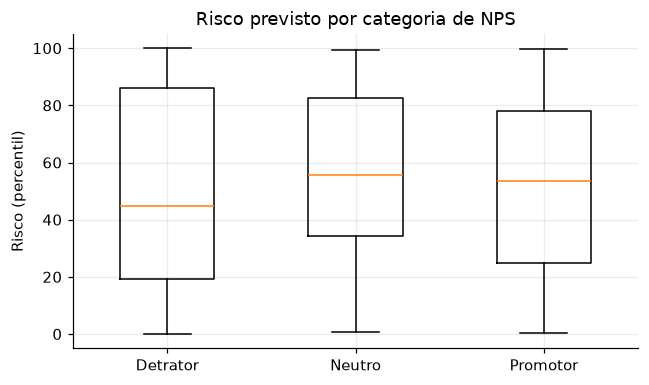

In [22]:
nps = oof.dropna(subset=["NOTA_NPS"]).copy()
det = nps["nps_categoria"] == "Detrator"
auc_det = roc_auc_score(det, nps["risco"])
mw = mannwhitneyu(nps.loc[det, "risco"], nps.loc[~det, "risco"], alternative="greater")
rho = spearmanr(nps["risco"], nps["NOTA_NPS"])
rho_s = spearmanr(nps["sentiment_index"], nps["NOTA_NPS"])
print(f"Reuniões com NPS: {len(nps)} (detratores: {det.sum()})")
print(f"Risco médio — detratores {nps.loc[det, 'risco'].mean():.1f} | demais {nps.loc[~det, 'risco'].mean():.1f}")
print(f"AUC (risco separa detratores): {auc_det:.2f} | Mann-Whitney unilateral p = {mw.pvalue:.3f}")
print(f"Spearman risco × NPS: {rho.statistic:+.2f} (p = {rho.pvalue:.3f}) | "
      f"sentimento × NPS: {rho_s.statistic:+.2f} (p = {rho_s.pvalue:.3f})")

fig, ax = plt.subplots(figsize=(6, 3.6))
order = ["Detrator", "Neutro", "Promotor"]
ax.boxplot([nps.loc[nps["nps_categoria"] == c, "risco"] for c in order], tick_labels=order, widths=0.5)
ax.set(title="Risco previsto por categoria de NPS", ylabel="Risco (percentil)")
fig.tight_layout()
fig.savefig(FIGURES / "06_risco_por_nps.png", bbox_inches="tight")

A defasagem entre a pesquisa de NPS e a reunião é grande, então repetimos o teste só com pesquisas
próximas da reunião:

In [23]:
survey = pd.to_datetime(meetings.set_index("ID_MEETING")["DT_ULTIMA_PESQUISA"], format="%Y-%m", errors="coerce")
meeting_date = pd.to_datetime(meetings.set_index("ID_MEETING")["DT_MEETING"])
nps["defasagem_meses"] = ((meeting_date - survey).dt.days / 30.4).reindex(nps.index)
print(f"Defasagem pesquisa → reunião: mediana {nps['defasagem_meses'].median():.0f} meses\n")
rows = []
for name, sub in [("todas", nps), ("pesquisa ≤ 6 meses", nps[nps["defasagem_meses"].abs() <= 6]),
                  ("pesquisa ≤ 3 meses", nps[nps["defasagem_meses"].abs() <= 3]),
                  ("só clientes (customer)", nps[nps["TP_RECURSO"] == "customer"])]:
    d = sub["nps_categoria"] == "Detrator"
    rows.append({"recorte": name, "reuniões": len(sub), "detratores": int(d.sum()),
                 "AUC risco": roc_auc_score(d, sub["risco"]),
                 "AUC sentimento (inverso)": roc_auc_score(d, -sub["sentiment_index"]),
                 "Spearman risco×NPS": spearmanr(sub["risco"], sub["NOTA_NPS"]).statistic})
pd.DataFrame(rows).set_index("recorte")

Defasagem pesquisa → reunião: mediana 14 meses



,reuniões,detratores,AUC risco,AUC sentimento (inverso),Spearman risco×NPS
recorte,,,,,
todas,310,49,0.451,0.462,-0.024
pesquisa ≤ 6 meses,91,10,0.317,0.460,0.106
pesquisa ≤ 3 meses,51,6,0.226,0.248,0.017
só clientes (customer),91,19,0.452,0.450,-0.037


**Resultado negativo, e reportado como tal.** O risco previsto **não separa detratores** (AUC ≈ 0,45,
perto de 0,5 = acaso; correlação com a nota ≈ 0), e restringir às pesquisas recentes não muda isso
(as amostras ficam pequenas: 6 a 10 detratores). As explicações mais prováveis estão nos dados, não
no modelo:

1. **O NPS é da conta, e é antigo.** A pesquisa precede a reunião em ~1 ano na mediana, e mede a
   relação da empresa com a TOTVS, não aquela conversa.
2. **Quem responde ao NPS geralmente não está na reunião.** Uma reunião de implantação com o time
   técnico diz pouco sobre a nota que a diretoria deu um ano antes.
3. **A maioria das reuniões é de pré-venda e projeto**, não de relacionamento — e um detrator em
   reunião de suporte pode estar justamente sendo bem atendido.

Consequência prática: **o score de risco deve ser usado como triagem de conversas** ("esta reunião
teve linguagem de insatisfação acima do normal"), **não como previsão de churn**. Validar previsão de
churn exige o desfecho real (cancelou / renovou), que a base não traz.

## 7. Recomendações de negócio (10 pts)

In [24]:
status_counts = oof["classificacao"].value_counts()
print("Distribuição das 1.126 reuniões por classificação:")
print((100 * status_counts / len(oof)).round(1).astype(str).add("%").to_string())
print(f"\nProdutos em mais reuniões: {', '.join(products_table.head(4).index)}")
print(f"Tempo total do notebook: {(time.time() - T0) / 60:.1f} min")

Distribuição das 1.126 reuniões por classificação:
classificacao
Saudável / acompanhamento    33.1%
Atenção                      31.5%
Oportunidade quente          15.3%
Conta em risco               15.3%
Negociação sensível           4.8%

Produtos em mais reuniões: Protheus, RM, Fluig, RD Station
Tempo total do notebook: 19.8 min


1. **Transformar as reuniões em uma fila diária priorizada.** Hoje as transcrições não são lidas por
   ninguém depois da reunião. Ordenar por *prioridade* e rotear por *classificação* dá um trabalho
   acionável: **"Conta em risco" → Customer Success em até 48h**; **"Oportunidade quente" → executivo
   de vendas em até 5 dias úteis**; **"Negociação sensível" → gestor da conta antes de qualquer
   proposta**. Por construção (percentil), cerca de 1 em cada 5 reuniões entra em nível alto em cada
   eixo — um volume que um time consegue tratar, e que pode ser apertado subindo o corte de 80.
2. **Usar as evidências, não só o número.** Cada score vem com os trechos que o justificam. O gestor
   lê três parágrafos em vez de uma transcrição de uma hora — é o que torna o alerta confiável o
   bastante para alguém agir.
3. **Cross-sell guiado pela dor citada.** Protheus, RM e Fluig dominam as conversas. Quando um cliente
   de ERP descreve fluxos de aprovação e documentos por e-mail sem citar o Fluig, o sistema sugere o
   Fluig; o mesmo vale para Techfin (crédito e cobrança), RD Station (leads) e TOTVS Cloud
   (servidor próprio, backup). É venda consultiva disparada pelo que o cliente disse, não por
   campanha.
4. **Inteligência competitiva.** Concorrentes citados alimentam *battlecards*. Atenção: "Oracle"
   aparece muito, mas na maior parte das vezes como **banco de dados ou nuvem** ("o banco é Oracle"),
   e só às vezes como ERP concorrente ("estou comparando vocês com a Oracle, com a NetSuite") — o
   dicionário precisa separar os dois sentidos antes de virar indicador de perda.
5. **Não vender o risco como previsão de churn** (seção 6.3). Ele é um termômetro da conversa. Para
   virar previsão, a TOTVS precisa ligar as reuniões ao desfecho (renovou / cancelou) — o próximo
   passo de dados mais valioso.
6. **Fechar o ciclo com o time comercial.** Um botão "o alerta procede / não procede" no CRM
   transforma cada uso em um **rótulo real**, que substitui progressivamente os rótulos fracos deste
   trabalho. Em poucos meses de uso há rótulos suficientes para re-treinar com supervisão de verdade.

## 8. Limitações e próximos passos (5 pts)

| Limitação | Efeito observado | Próximo passo |
|---|---|---|
| **Rótulos fracos** (léxico), sem conjunto anotado por humanos | Precisão por trecho baixa no risco; o teto do modelo é o que a regra define | Anotar ~500 trechos com dois anotadores (concordância *kappa*) para ter um conjunto-ouro de avaliação; usar o feedback do CRM (rec. 6) para treino |
| **Sem desfecho de churn**; NPS antigo e da conta | Validação com NPS sem sinal (6.3) | Ligar reunião → renovação/cancelamento; NPS/CSAT transacional logo após a reunião |
| **Reunião interna × com cliente não é distinguida** | Stand-up interno sobre bug vira "conta em risco" (6.1, caso 10) | Classificador de tipo de reunião (a base tem `FLG_EXTERNO`, mas 98% é `True`) |
| **Papéis dos locutores desconhecidos** (`LOCUTOR N`, diarização ruidosa) | Fala do vendedor ("se o cliente cancelar...") conta como risco do cliente | Identificar vendedor × cliente (quem compartilha tela, quem apresenta) e pontuar só a fala do cliente |
| **Risco expresso como barganha** (preço, concorrente) não é capturado | Caso 05 das sintéticas | Rótulos de "objeção/negociação" separados de "insatisfação" |
| **Vocabulário de ERP colide com o de venda e de risco** | Demonstrações de Compras, RH e Custos geram falsos sinais (seções 2 e 3.4) | Contexto de demonstração como variável (tela compartilhada, densidade de termos de módulo) |
| **Percentil sobre reuniões longas** | Transcrições muito curtas tendem a extremos, porque têm menos trechos neutros diluindo o pico | Referência por faixa de duração |
| **Modelos de *bag-of-words*** | Não entendem negação longa nem ironia | Destilar um modelo de linguagem PT-BR (BERTimbau) usando o LLM que a NORA já usa (saída em JSON Schema estrito) como rotulador |
| **Protótipo fora do produto** | Roda como CLI e Streamlit, não dentro da NORA | Expor `analyze()` como etapa do worker NLP da NORA, ao lado do TF-IDF baseline que ele já usa |